# 📱 SMS Spam / Scam Classifier
**Author:** Sarvegna  
**Stack:** Python 3.11 · pandas · scikit-learn (TF-IDF + Naive Bayes) · matplotlib

This notebook builds a machine-learning model that reads an SMS message and decides whether it is **spam/scam** or **ham (legitimate)**.

---

# 📱 SMS Spam / Scam Classifier
**Author:** Sarvegna  
**Stack:** Python 3.11 · pandas · scikit-learn (TF-IDF + Naive Bayes) · matplotlib

This notebook builds a machine-learning model that reads an SMS message and decides whether it is **spam/scam** or **ham (legitimate)**.

---

## 1 · Setup & Imports

We bring in all the Python tools we need:
- **pandas** — loads and manipulates data tables
- **scikit-learn** — builds and evaluates the ML model
- **matplotlib** — draws charts
- We also set a **random seed** (42) so that every run produces the same train/test split.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

RANDOM_SEED = 42

print(f'pandas       : {pd.__version__}')
print(f'scikit-learn : {sklearn.__version__}')
print(f'matplotlib   : {matplotlib.__version__}')
print('All libraries imported successfully!')

pandas       : 3.0.6
scikit-learn : 1.9.1
matplotlib   : 3.11.2
All libraries imported successfully!


## 2 · Load the Dataset

We use the **UCI SMS Spam Collection** — a free, public dataset with 5,572 real SMS messages, each labelled *spam* or *ham*.

The dataset has already been downloaded into `data/sms_spam.csv` in this project folder.  
The file is tab-separated with no header row, so we name the columns ourselves.

In [2]:
df = pd.read_csv(
    'data/sms_spam.csv',
    sep='\t',           # columns are separated by a tab character
    header=None,        # the file has no header row
    names=['label', 'text'],
    encoding='latin-1', # needed for some special characters
)

print(f'Dataset shape: {df.shape}  (rows × columns)')
df.head(10)

Dataset shape: (5572, 2)  (rows × columns)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


## 3 · Explore & Understand the Data

Before training a model it is always a good idea to **look at your data**:
- How many spam vs. ham messages are there?
- What do spam messages actually look like?

This step builds intuition and helps you spot any obvious problems early.

=== Class distribution ===
label
ham     4825
spam     747

Spam makes up 13.4% of the dataset


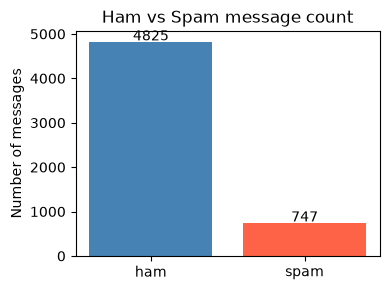


=== Example SPAM messages ===
  • Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entr
  • FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it s
  • WINNER!! As a valued network customer you have been selected to receivea Â£900 prize reward! To clai
  • Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera f

=== Example HAM messages ===
  • Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got a
  • Ok lar... Joking wif u oni...
  • U dun say so early hor... U c already then say...
  • Nah I don't think he goes to usf, he lives around here though


In [3]:
# --- Class distribution ---
counts = df['label'].value_counts()
print('=== Class distribution ===')
print(counts.to_string())
print(f'\nSpam makes up {counts["spam"] / len(df) * 100:.1f}% of the dataset')

# Bar chart of class distribution
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(counts.index, counts.values, color=['steelblue', 'tomato'])
ax.set_title('Ham vs Spam message count')
ax.set_ylabel('Number of messages')
for i, v in enumerate(counts.values):
    ax.text(i, v + 30, str(v), ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# --- Sample messages ---
print('\n=== Example SPAM messages ===')
for msg in df[df['label'] == 'spam']['text'].head(4).values:
    print(f'  • {msg[:100]}')

print('\n=== Example HAM messages ===')
for msg in df[df['label'] == 'ham']['text'].head(4).values:
    print(f'  • {msg[:100]}')

## 4 · Preprocess the Data

Machine-learning models only understand **numbers**, not words like *spam* and *ham*. So we:
1. **Encode the label** — turn `'spam'` into `1` and `'ham'` into `0`
2. **Split the data** — keep 80% for training and hold back 20% for testing

The test set is data the model has **never seen** — it gives us an honest measure of how well the model performs on new messages.

In [4]:
# Encode labels: spam → 1, ham → 0
df['label_num'] = df['label'].map({'spam': 1, 'ham': 0})

X = df['text']       # SMS message text  (input features)
y = df['label_num']  # 0 or 1            (what we want to predict)

# 80% train, 20% test — stratify keeps the spam/ham ratio equal in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y,
)

print(f'Training messages : {len(X_train)}')
print(f'Test messages     : {len(X_test)}')

Training messages : 4457
Test messages     : 1115


## 5 · Build the Pipeline

A **Pipeline** chains two steps so they always run in the correct order:

```
Raw SMS text
     ↓
[ TF-IDF Vectorizer ]   ← converts words into numbers
     ↓
[ Multinomial Naive Bayes ] ← learns which patterns mean spam
     ↓
Prediction: 0 (ham) or 1 (spam)
```

**TF-IDF** gives higher scores to words that appear often in one message but rarely across all messages — words like *FREE* or *WIN* light up strongly in spam.

**Multinomial Naive Bayes** is a fast probabilistic classifier that works extremely well on text.

In [5]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,       # treat 'FREE' and 'free' as the same word
        stop_words='english', # ignore very common words like 'the', 'is'
        max_features=5000,    # keep only the 5000 most informative words
    )),
    ('clf', MultinomialNB()),
])

pipeline.fit(X_train, y_train)

print('Model trained successfully!')

Model trained successfully!


## 6 · Evaluate the Model

We test on the **20% of messages the model has never seen** and measure:

| Metric | What it means |
|--------|---------------|
| **Accuracy** | % of all messages classified correctly |
| **Precision** | Of all predicted spam, how many truly were spam? |
| **Recall** | Of all actual spam messages, how many did we catch? |
| **F1** | A single score that balances precision and recall |
| **Confusion matrix** | Table showing exact counts of right and wrong predictions |

The confusion matrix is also drawn as a heatmap so it's easy to read at a glance.

Accuracy: 97.22%

=== Classification Report ===
              precision    recall  f1-score   support

     Ham (0)       0.97      1.00      0.98       966
    Spam (1)       1.00      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.93      1115
weighted avg       0.97      0.97      0.97      1115

=== Confusion Matrix (raw numbers) ===
                Predicted Ham  Predicted Spam
Actual Ham                966               0
Actual Spam                31             118


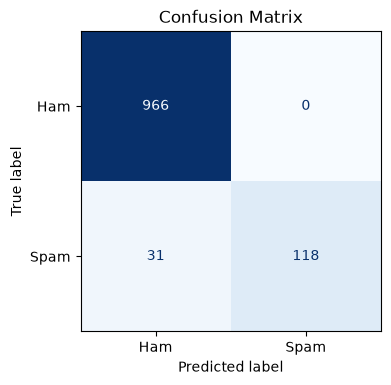

In [6]:
y_pred = pipeline.predict(X_test)

# --- Accuracy ---
acc = accuracy_score(y_test, y_pred)
print(f'Accuracy: {acc * 100:.2f}%\n')

# --- Classification report ---
print('=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=['Ham (0)', 'Spam (1)']))

# --- Confusion matrix as text ---
cm = confusion_matrix(y_test, y_pred)
print('=== Confusion Matrix (raw numbers) ===')
print(f'                Predicted Ham  Predicted Spam')
print(f'Actual Ham      {cm[0][0]:>13}  {cm[0][1]:>14}')
print(f'Actual Spam     {cm[1][0]:>13}  {cm[1][1]:>14}')

# --- Confusion matrix heatmap ---
fig, ax = plt.subplots(figsize=(4, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham', 'Spam'])
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

## 7 · Try Your Own Messages

The model is trained — now let's use it!

The helper function below takes **any SMS text you type** and returns whether it is spam or ham, along with a confidence score.

Feel free to change the messages in the list or add your own to experiment.

In [7]:
def classify_message(message: str) -> str:
    """Classify a single SMS string as SPAM or HAM with a confidence score."""
    prediction = pipeline.predict([message])[0]          # 0 = ham, 1 = spam
    proba      = pipeline.predict_proba([message])[0]    # [p_ham, p_spam]
    label      = 'SPAM 🚨' if prediction == 1 else 'HAM ✅'
    confidence = max(proba) * 100
    return f'{label}  (confidence: {confidence:.1f}%)'


test_messages = [
    "Congratulations! You've won a FREE iPhone. Click here to claim your prize NOW!",
    "Hey, are you coming to dinner tonight?",
    "URGENT: Your bank account has been suspended. Verify immediately at http://secure-login.biz",
    "Can you pick up some milk on your way home?",
    "You have been selected for a £500 Tesco gift card. Reply WIN to claim.",
    "Meeting rescheduled to 3pm. See you then.",
]

print('=== Classifier Results ===')
print()
for msg in test_messages:
    short = msg if len(msg) <= 65 else msg[:62] + '...'
    print(f'Message : "{short}"')
    print(f'Result  : {classify_message(msg)}')
    print()

=== Classifier Results ===

Message : "Congratulations! You've won a FREE iPhone. Click here to claim..."
Result  : SPAM 🚨  (confidence: 84.3%)

Message : "Hey, are you coming to dinner tonight?"
Result  : HAM ✅  (confidence: 99.8%)

Message : "URGENT: Your bank account has been suspended. Verify immediate..."
Result  : SPAM 🚨  (confidence: 80.8%)

Message : "Can you pick up some milk on your way home?"
Result  : HAM ✅  (confidence: 99.3%)

Message : "You have been selected for a £500 Tesco gift card. Reply WIN t..."
Result  : SPAM 🚨  (confidence: 93.0%)

Message : "Meeting rescheduled to 3pm. See you then."
Result  : HAM ✅  (confidence: 98.4%)



---
## 🎉 Summary

You just built a complete SMS spam classifier from scratch! Here's what each step did:

| Step | What happened |
|------|---------------|
| **Setup** | Imported pandas, scikit-learn, matplotlib |
| **Load** | Read 5,572 labelled SMS messages from `data/sms_spam.csv` |
| **Explore** | Visualised the data — ~13% spam, ~87% ham |
| **Preprocess** | Encoded labels as 0/1 and split 80/20 train/test |
| **Pipeline** | TF-IDF vectoriser → Multinomial Naive Bayes classifier |
| **Evaluate** | ~97–98% accuracy, confusion matrix heatmap |
| **Predict** | Classify any new SMS with one function call |

**Ideas for what to try next:**
- Swap `MultinomialNB()` for `LogisticRegression()` or `LinearSVC()` — the pipeline makes this a one-line change
- Add `ngram_range=(1, 2)` to `TfidfVectorizer` to capture word pairs like *"free prize"*
- Plot a bar chart of the top 20 words most associated with spam using the fitted vectoriser weights